# 04 · 非线性 Burgers 方程与可靠数据生成（进阶）

**前置：** 03；数值时间积分基础。**目标：** 给非线性 PDE 生成参考解，检查参考算法，再训练 FNO。

$u_t+u u_x=\nu u_{xx}$，周期 $x\in[0,1)$，$\nu=0.03$，$T=0.1$。学习初值到固定终止时刻的映射。非线性产生新频率，因此不能像热方程一样仅乘一个解析衰减因子。

使用 Fourier 伪谱空间离散、2/3 截断和 RK4 时间积分。它是教学求解器，适用于本章温和的光滑初值与黏性；改变黏性、网格或幅度后必须重新检查时间步稳定性与收敛。

## 原理详解 A：Burgers 的非线性、频率耦合与守恒结构

Burgers 方程
$$
u_t+u u_x=\nu u_{xx}
$$
同时包含对流和黏性扩散。速度场就是 u 自己，因此较大幅度区域可以传播得更快，并使梯度变陡。正黏性会平滑这些梯度，本章选取温和参数与光滑初值，避免把教程求解器用于难以解析的尖锐结构。

把对流项写成 $\partial_x(u^2/2)$，得到守恒形式
$$
u_t=-\partial_x(u^2/2)+\nu\partial_{xx}u.
$$
在周期域积分，边界通量相互抵消，故
$$
\frac d{dt}\int_0^1u\,dx=0.
$$
再乘 u 并积分，周期分部积分给出
$$
\frac d{dt}\frac12\int_0^1u^2\,dx
=-\nu\int_0^1|u_x|^2\,dx\le0.
$$
均值守恒和能量不增是检查参考解的依据，也能揭示只优化数据 MSE 的模型是否偏离物理结构。

频谱中，平方不是逐频率平方，而是卷积：
$$
\widehat{u^2}_k=\sum_{p+q=k}\widehat u_p\widehat u_q.
$$
即使初值只有低频，也会产生频率相加后的新模式。所以热方程的独立衰减公式不再适用。

## 原理详解 B：伪谱法、混叠与 2/3 截断

伪谱法用 FFT 计算导数：
$$
\widehat{\partial_xu}_k=i2\pi k\widehat u_k,\qquad
\widehat{\partial_{xx}u}_k=-(2\pi k)^2\widehat u_k,
$$
但在物理网格计算 $u^2/2$，再变回频谱。它利用了物理空间逐点乘法与频谱空间精确模式微分各自的便利。

有限网格只能分辨有限频率。若两个保留模式相乘产生超出可分辨范围的频率，离散 FFT 会将其折回较低频率，这就是混叠。它会污染原本应属于低频的数值信息，不能仅靠减小 dt 解决。

对二次非线性，常见处理是把保留带宽限制到约 $|k|<N/3$，也称 2/3 去混叠规则：保留原可表示模式范围的大约三分之二。本章用 $\lfloor(N-1)/3\rfloor$ 避开边界频率，并在乘法前及乘法后的频谱中投影。另一种处理是 3/2 零填充后计算乘积，再截回原频带。

“谱导数很精确”仅对当前被表示的光滑频率成立。截断后的参考方程已有空间离散误差；降低 dt 不能恢复被删除的高频。代码同时做时间步减半和空间网格加密，分别检查这两类误差。

## 原理详解 C：RK4、稳定性与时间映射

空间离散后，PDE 变成有限维 ODE $\dot{\mathbf u}=F_h(\mathbf u)$。经典 RK4 使用
$$
k_1=F_h(u_n),\quad k_2=F_h(u_n+\tfrac{\Delta t}{2}k_1),\quad
k_3=F_h(u_n+\tfrac{\Delta t}{2}k_2),\quad
k_4=F_h(u_n+\Delta t\,k_3),
$$
$$
u_{n+1}=u_n+\frac{\Delta t}{6}(k_1+2k_2+2k_3+k_4).
$$
平滑且稳定时，固定终止时间的时间误差通常为 $O(\Delta t^4)$，但四阶精度不表示无条件稳定。

扩散模式的特征值是 $-\nu(2\pi k)^2$，高频要求更小 dt；对流还受速度幅度和网格尺度约束。空间分辨率提高两倍，扩散限制往往使显式步长需要缩小到约四分之一。这个缩放是稳定性估计，具体配置仍需实际收敛检查。

下面的 solver 用双精度积分，最后把标签转成 float32。因此很小的时间步差异可能在转成标签精度后变成打印出的零；不能把“差异为零”解释成没有数值误差。

模型学习的是 $S_T:u_0\mapsto u(T)$。连续 PDE 的精确解映射具有半群性质 $S_{2T}=S_T\circ S_T$，但一个只在原始初值分布上监督训练的近似映射未必可靠满足它。反复调用会把预测误差和分布漂移累积到后续输入，需要单独设计长时间验证。

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "tutorial_utils.py").exists():
    ROOT = ROOT / "neural_operator_tutorials"
if not (ROOT / "tutorial_utils.py").exists():
    raise FileNotFoundError("Please start Jupyter in PINO or neural_operator_tutorials")
sys.path.insert(0, str(ROOT))
import torch
get_ipython().run_line_magic('matplotlib', 'inline')
from tutorial_utils import *
seed_all()
print("device:", DEVICE, "| smoke:", SMOKE)


device: cpu | smoke: False


## 1. 先写可检验的参考求解器

用 $-(u^2/2)_x$ 写对流项，以保守形式计算。2/3 截断抑制二次乘积的混叠，初值和每个时间步也投影回保留的频带。

显式 RK4 的稳定性受扩散 $\nu k_{\max}^2\Delta t$ 和对流约束影响。默认 $N=64,\Delta t=0.0005$ 是本章的保守选择；不要随意套到大网格。

In [2]:
def burgers_solve(initial,nu=0.03,time=0.1,dt=0.0005):
    u = initial.double().clone()
    n = u.shape[-1]
    freq = torch.fft.rfftfreq(n,d=1/n).to(u)
    wave = 2*torch.pi*freq
    mask = freq <= (n-1)//3
    def project(v):
        return torch.fft.irfft(torch.fft.rfft(v)*mask,n=n)
    def rhs(v):
        v = project(v)
        vf = torch.fft.rfft(v)
        flux = torch.fft.rfft(0.5*v.square())*mask
        return torch.fft.irfft(-1j*wave*flux-nu*wave.square()*vf,n=n)
    steps = int(np.ceil(time/dt)); h = time/steps
    u = project(u)
    for _ in range(steps):
        k1 = rhs(u); k2 = rhs(u+h*k1/2)
        k3 = rhs(u+h*k2/2); k4 = rhs(u+h*k3)
        u = project(u+h*(k1+2*k2+2*k3+k4)/6)
    if not torch.isfinite(u).all():
        raise FloatingPointError("Solver unstable: reduce dt/check grid and amplitudes")
    return u.float()

ntrain,ntest = counts(192,48)
x = torch.arange(64)/64
atrain,aval,atest = torch.randn(ntrain,8),torch.randn(ntest,8),torch.randn(ntest,8)
u0 = 0.3*periodic_data(atrain,x)
v0 = 0.3*periodic_data(aval,x)
t0 = 0.3*periodic_data(atest,x)
ut,vt,tt = burgers_solve(u0),burgers_solve(v0),burgers_solve(t0)
print("data:",u0.shape,ut.shape)

data: torch.Size([192, 64]) torch.Size([192, 64])


## 2. 数据质量检查必须先于训练

时间步减半检查时间误差；在 128 点上计算同一初值并每隔一点评估空间误差。零模对应均值，应被保守形式保持。周期积分可以用样本均值近似。黏性使 $\int u^2/2$ 不增。检查通过说明这些案例可信，不构成任意配置的稳定性证明。

time refinement: 0.0 space refinement: 3.7469845892701414e-08 mean drift: 3.026798367500305e-09


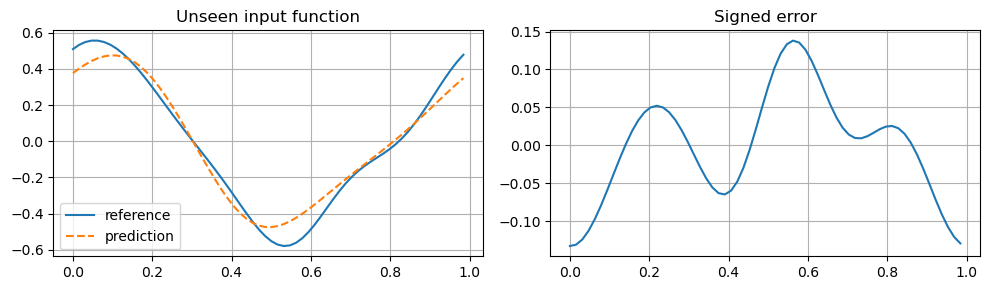

In [3]:
small_step = burgers_solve(t0[:2],dt=0.00025)
time_error = relative_l2(small_step,tt[:2]).mean().item()
xfine = torch.arange(128)/128
fine0 = 0.3*periodic_data(atest[:2],xfine)
fine = burgers_solve(fine0,dt=0.000125)
space_error = relative_l2(fine[:,::2],tt[:2]).mean().item()
mean_drift = (tt.mean(-1)-t0.mean(-1)).abs().max().item()
print("time refinement:",time_error,"space refinement:",space_error,"mean drift:",mean_drift)
assert time_error<1e-3 and space_error<0.02
assert mean_drift<1e-6
assert (tt.square().mean(-1)<=t0.square().mean(-1)+1e-6).all()
plot_1d(x,t0,tt)

## 3. 使用上一章的同类 FNO 架构

代码再次完整展示，方便独立运行。改变的是 PDE 数据与映射，网络无需知道数值求解器的内部步骤。

In [4]:
class SpectralConv1d(nn.Module):
    """[batch, in_channels, N] -> [batch, out_channels, N]."""
    def __init__(self, cin, cout, modes):
        super().__init__()
        self.modes = modes
        self.weight = nn.Parameter(
            torch.randn(cin, cout, modes, dtype=torch.cfloat) / (cin*cout)**0.5)

    def forward(self, v):
        n = v.shape[-1]
        vf = torch.fft.rfft(v, dim=-1)
        m = min(self.modes, vf.shape[-1])
        out = torch.zeros(v.shape[0], self.weight.shape[1], vf.shape[-1],
                          dtype=vf.dtype, device=v.device)
        out[..., :m] = torch.einsum("bim,iom->bom", vf[..., :m], self.weight[..., :m])
        # Always specify n: odd-length grids would otherwise reconstruct incorrectly.
        return torch.fft.irfft(out, n=n, dim=-1)

class FNO1d(nn.Module):
    def __init__(self, width=24, modes=10, depth=3):
        super().__init__()
        self.lift = nn.Linear(3, width)
        self.spectral = nn.ModuleList([SpectralConv1d(width, width, modes) for _ in range(depth)])
        self.local = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(depth)])
        self.project = nn.Sequential(nn.Linear(width, 32), nn.GELU(), nn.Linear(32, 1))

    def forward(self, a):
        # a: [B,N]; periodic positional features avoid an artificial seam at x=1.
        x = torch.arange(a.shape[-1], device=a.device, dtype=a.dtype) / a.shape[-1]
        pos = torch.stack(((2*torch.pi*x).sin(), (2*torch.pi*x).cos()), -1)
        inp = torch.cat((a[..., None], pos[None].expand(len(a), -1, -1)), -1)
        v = self.lift(inp).transpose(1, 2)
        for spectral, local in zip(self.spectral, self.local):
            v = torch.nn.functional.gelu(spectral(v) + local(v))
        return self.project(v.transpose(1, 2)).squeeze(-1)


epoch    1 | train MSE 7.275e-02 | val relative L2 0.999


epoch   30 | train MSE 6.126e-06 | val relative L2 0.011


epoch   60 | train MSE 2.014e-06 | val relative L2 0.006


epoch   90 | train MSE 8.695e-07 | val relative L2 0.004


epoch  120 | train MSE 5.751e-07 | val relative L2 0.003


epoch  150 | train MSE 4.214e-07 | val relative L2 0.003


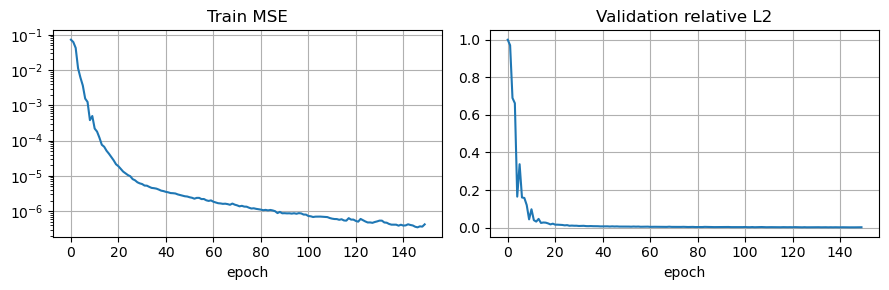

Test relative L2: mean=0.0030, median=0.0022, max=0.0271


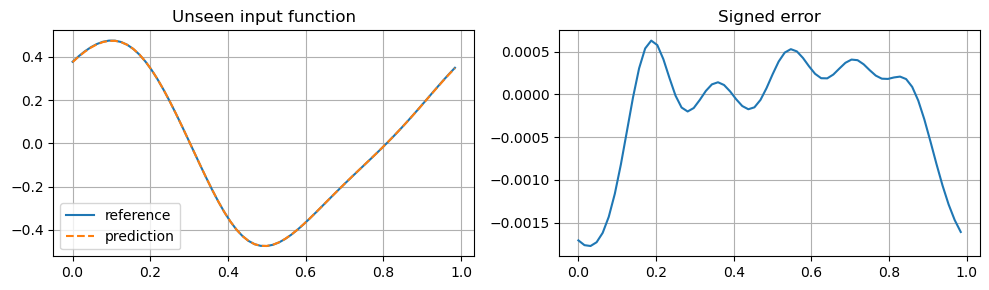

Predicted mean drift: 0.00033206737134605646
Reference mean drift: 6.317956713353112e-10


In [5]:
model = FNO1d(width=24,modes=10)
history = fit(model,u0,ut,v0,vt,steps=epochs(150))
plot_history(history)
pred,error = report(model,t0,tt)
plot_1d(x,tt,pred)
print("Predicted mean drift:",(pred.mean(-1)-t0.mean(-1)).abs().mean().item())
print("Reference mean drift:",(tt.mean(-1)-t0.mean(-1)).abs().mean().item())

## 4. 学到固定时间映射不等于学到时间步推进

网络输入对应 $t=0$，输出对应 $t=0.1$。把输出反复送回网络，会遇到训练分布漂移；误差累积需单独评估。只看终止时刻误差也不能判断质量守恒。

**练习：** ① 减小黏性时逐步降低 dt，并记录收敛；② 加大初值幅度，看能量、均值和误差；③ 在训练损失加入均值守恒项；④ 训练多时刻模型，再设计独立的长时间测试。

本章不包含激波捕捉、不可压 Navier–Stokes 或工业规模 CFD。